# Outdoor Hazard Object Detection with Ultralytics YOLO

## Classes

0. Car
1. Person
2. Stairs
3. Traffic sign
4. Electrical pole
5. Road
6. Manhole
7. Tree
8. Pedestrian crosswalk
9. Traffic cone
10. Bench
11. Electrical box

## Set up dataset

In [18]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
%pip install -q ultralytics

## Use filtered dataset for train and validation
- 2455 images filtered from the original dataset (https://www.kaggle.com/datasets/abtinzandi/obstacle-detection-dataset)

In [20]:
from pathlib import Path
import random
import shutil
import yaml

MYDRIVE_ROOT = Path('/content/drive/MyDrive')
MYDRIVE_PROJECT_ROOT = MYDRIVE_ROOT / 'IAT 360 Project Files'
FILTERED_ROOT = MYDRIVE_PROJECT_ROOT / 'filtered_data'
FILTERED_IMAGES_DIR = FILTERED_ROOT / 'images'
FILTERED_LABELS_DIR = FILTERED_ROOT / 'labels'

# Check that the dataset can be found
if not FILTERED_IMAGES_DIR.is_dir():
    raise FileNotFoundError(f'Filtered image folder not found: {FILTERED_IMAGES_DIR}')
if not FILTERED_LABELS_DIR.is_dir():
    raise FileNotFoundError(f'Filtered labels folder not found: {FILTERED_LABELS_DIR}')

class_names = [
    'Car', 'Person', 'Stairs', 'Traffic sign', 'Electrical pole', 'Road',
    'Manhole', 'Tree', 'Pedestrian crosswalk', 'Traffic cone', 'Bench', 'Electrical box',
]
class_count = len(class_names)

print(f'Using filtered dataset: {FILTERED_ROOT}')
print(f'Target classes: {class_names}')

Using filtered dataset: /content/drive/MyDrive/IAT 360 Project Files/filtered_data
Target classes: ['Car', 'Person', 'Stairs', 'Traffic sign', 'Electrical pole', 'Road', 'Manhole', 'Tree', 'Pedestrian crosswalk', 'Traffic cone', 'Bench', 'Electrical box']


## Check dataset files

Training images and labels are already in YOLO format. This section checks that folders are available, image and label filenames match, and one pair can be read.

In [21]:
# Find images and label files
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png'}
image_paths = sorted(
    path for path in FILTERED_IMAGES_DIR.rglob('*')
    if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
)
image_paths_by_stem = {
    path.relative_to(FILTERED_IMAGES_DIR).with_suffix('').as_posix(): path
    for path in image_paths
}
label_paths_by_stem = {
    path.relative_to(FILTERED_LABELS_DIR).with_suffix('').as_posix(): path
    for path in FILTERED_LABELS_DIR.rglob('*.txt')
}
if not image_paths:
    raise ValueError(f'No images found in {FILTERED_IMAGES_DIR}')
if len(image_paths_by_stem) != len(image_paths):
    raise ValueError('Multiple filtered images share the same filename')

# Check for matching image/label pairs and missing files
image_files = set(image_paths_by_stem)
label_files = set(label_paths_by_stem)
extra_images = image_files - label_files
extra_labels = label_files - image_files
print(f'Images without matching labels: {sorted(extra_images)}')
print(f'Labels without matching images: {sorted(extra_labels)}')

matched_stems = image_files & label_files
if not matched_stems:
    raise ValueError('No images have matching labels in dataset.')

# Create a copy of data to a new folder for training
pairs = [
    (image_paths_by_stem[stem], label_paths_by_stem[stem])
    for stem in sorted(matched_stems)
]
print(f'Matching image/label pairs: {len(pairs)}')
print(f'Unmatched images ignored: {len(extra_images)}')
print(f'Unmatched labels ignored: {len(extra_labels)}')

# Load one image and label for visual confirmation that everything is working
from PIL import Image
with Image.open(pairs[0][0]) as sample_image:
    sample_image.load()
pairs[0][1].read_text(encoding='utf-8')
print('Sample image and label loaded successfully.')

Images without matching labels: []
Labels without matching images: []
Matching image/label pairs: 2455
Unmatched images ignored: 0
Unmatched labels ignored: 0
Sample image and label loaded successfully.


## Create YOLO train/validation folder structure

In [22]:
SEED = 42
PREPARED_DIR = FILTERED_ROOT / 'yolo_dataset'

random.Random(SEED).shuffle(pairs)
split_index = int(len(pairs) * 0.8)
source_splits = {'train': pairs[:split_index], 'val': pairs[split_index:]}
prepared_splits = {}

# Create YOLO's images/<split> and labels/<split> folders, then copy each matched pair.
for split_name, source_pairs in source_splits.items():
    image_split_dir = PREPARED_DIR / 'images' / split_name
    label_split_dir = PREPARED_DIR / 'labels' / split_name
    for split_dir in (image_split_dir, label_split_dir):
        if split_dir.exists():
            shutil.rmtree(split_dir)
        split_dir.mkdir(parents=True, exist_ok=True)
    split_pairs = []
    for image_path, label_path in source_pairs:
        relative_path = image_path.relative_to(FILTERED_IMAGES_DIR)
        prepared_image = image_split_dir / relative_path
        prepared_label = label_split_dir / relative_path.with_suffix('.txt')
        prepared_image.parent.mkdir(parents=True, exist_ok=True)
        prepared_label.parent.mkdir(parents=True, exist_ok=True)
        # use copyfile instead of copy to avoid perms issues on google drive
        shutil.copyfile(image_path, prepared_image)
        shutil.copyfile(label_path, prepared_label)
        split_pairs.append((prepared_image, prepared_label))
    prepared_splits[split_name] = split_pairs

# Keep the prepared pairs available for visualization and report each split size.
training_pairs = prepared_splits['train']
validation_pairs = prepared_splits['val']
print(f'Train images: {len(training_pairs)}')
print(f'Validation images: {len(validation_pairs)}')

Train images: 1964
Validation images: 491


## Prepare final test set

In [23]:
# Find test data in drive
TEST_SOURCE_DIR = MYDRIVE_PROJECT_ROOT / 'Images and labels'
TEST_SOURCE_IMAGES = TEST_SOURCE_DIR / 'images'
TEST_SOURCE_LABELS = TEST_SOURCE_DIR / 'labels'
if not TEST_SOURCE_IMAGES.is_dir() or not TEST_SOURCE_LABELS.is_dir():
    raise FileNotFoundError(f'Expected test images and labels under {TEST_SOURCE_DIR}')

# class order is different than test set, so map its IDs to the model's class IDs.
test_class_names = [
    'Bench', 'Car', 'Electrical box', 'Electrical pole', 'Manhole',
    'Pedestrian crosswalk', 'Person', 'Road', 'Stairs', 'Traffic cone',
    'Traffic sign', 'Tree',
]
test_to_model_class = {
    test_id: class_names.index(class_name)
    for test_id, class_name in enumerate(test_class_names)
}

# Match test image/label files by shared filename (e.g. test_00).
test_image_paths = {
    path.stem: path for path in TEST_SOURCE_IMAGES.iterdir()
    if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
}
test_label_paths = {
    path.stem: path for path in TEST_SOURCE_LABELS.glob('*.txt')
}
test_image_stems = set(test_image_paths)
test_label_stems = set(test_label_paths)
print(f'Test images without labels: {sorted(test_image_stems - test_label_stems)}')
print(f'Test labels without images: {sorted(test_label_stems - test_image_stems)}')
test_stems = sorted(test_image_stems & test_label_stems)
if not test_stems:
    raise ValueError(f'No matching test image/label pairs found in {TEST_SOURCE_DIR}')

# Create copy of test data to avoid changing the original files
test_images_dir = PREPARED_DIR / 'images' / 'test'
test_labels_dir = PREPARED_DIR / 'labels' / 'test'
for test_dir in (test_images_dir, test_labels_dir):
    if test_dir.exists():
        shutil.rmtree(test_dir)
    test_dir.mkdir(parents=True, exist_ok=True)

# Copy each image and rewrite only its label class ID
for stem in test_stems:
    source_image = test_image_paths[stem]
    source_label = test_label_paths[stem]
    shutil.copyfile(source_image, test_images_dir / source_image.name)
    remapped_rows = []
    for line in source_label.read_text(encoding='utf-8').splitlines():
        fields = line.split()
        if fields:
            fields[0] = str(test_to_model_class[int(fields[0])])
            remapped_rows.append(' '.join(fields))
    (test_labels_dir / source_label.name).write_text(
        '\n'.join(remapped_rows) + ('\n' if remapped_rows else ''),
        encoding='utf-8',
    )

print(f'Prepared {len(test_stems)} held-out test image/label pairs.')

Test images without labels: []
Test labels without images: []
Prepared 100 held-out test image/label pairs.


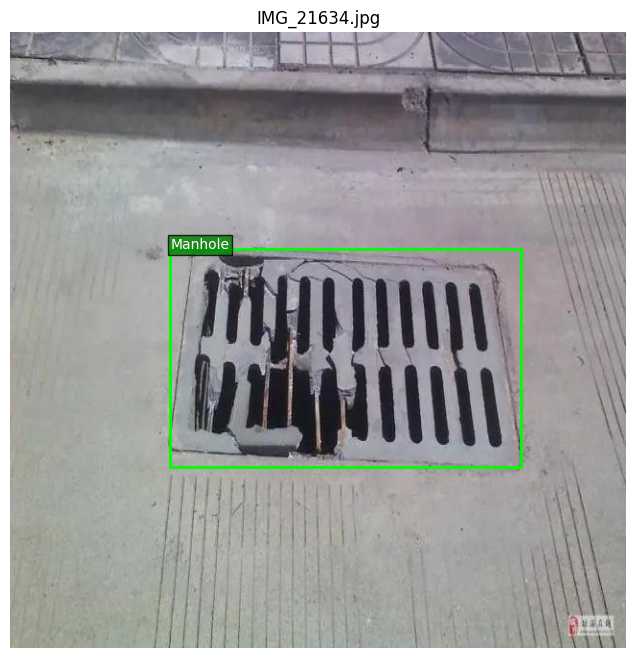

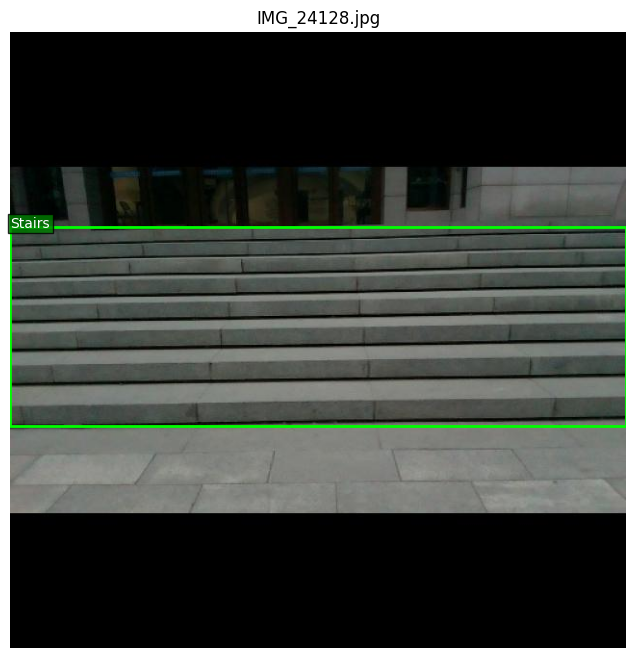

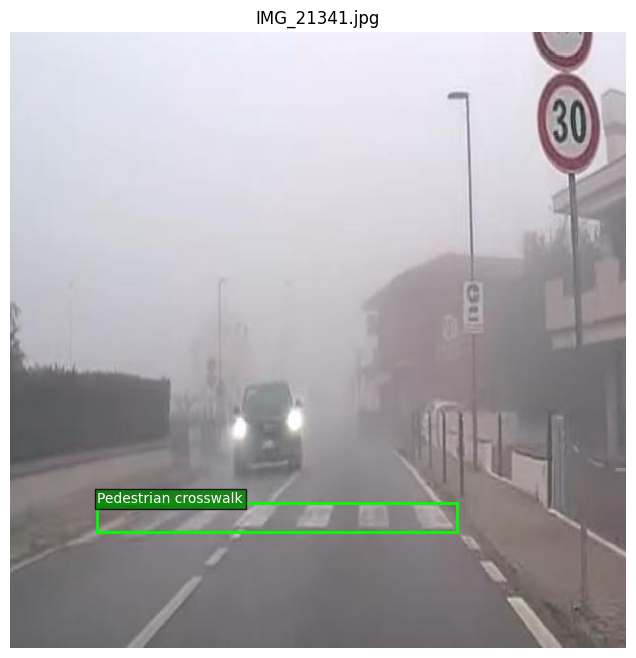

In [24]:
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Preview three training images and draw bounding boxes
for image_path, label_path in training_pairs[:3]:
    with Image.open(image_path) as image_file:
        image = image_file.convert('RGB')

    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(image)
    image_width, image_height = image.size

    for line in label_path.read_text(encoding='utf-8').splitlines():
        fields = line.split()
        class_id = int(fields[0])
        x_center, y_center, width, height = map(float, fields[1:])
        x_min = (x_center - width / 2) * image_width
        y_min = (y_center - height / 2) * image_height
        box_width = width * image_width
        box_height = height * image_height

        ax.add_patch(Rectangle(
            (x_min, y_min), box_width, box_height,
            fill=False, edgecolor='lime', linewidth=2,
        ))
        ax.text(
            x_min, y_min, class_names[class_id], color='white',
            bbox={'facecolor': 'green', 'alpha': 0.8, 'pad': 2},
        )

    ax.set_title(image_path.name)
    ax.axis('off')
    plt.show()
    plt.close(fig)

## Make Ultralytics dataset YAML

In [25]:
PREPARED_YAML = PREPARED_DIR / 'config.yaml'
prepared_config = {
    'path': str(PREPARED_DIR.resolve()),
    'train': str((PREPARED_DIR / 'images' / 'train').resolve()),
    'val': str((PREPARED_DIR / 'images' / 'val').resolve()),
    'test': str((PREPARED_DIR / 'images' / 'test').resolve()),
    'nc': class_count,
    'names': dict(enumerate(class_names)),
}
PREPARED_YAML.write_text(yaml.safe_dump(prepared_config, sort_keys=False), encoding='utf-8')
print(PREPARED_YAML.read_text(encoding='utf-8'))

path: /content/drive/.shortcut-targets-by-id/1Hj3D4xNnBZgB3Qkb4oM2viOQo_ovLck-/IAT
  360 Project Files/filtered_data/yolo_dataset
train: /content/drive/.shortcut-targets-by-id/1Hj3D4xNnBZgB3Qkb4oM2viOQo_ovLck-/IAT
  360 Project Files/filtered_data/yolo_dataset/images/train
val: /content/drive/.shortcut-targets-by-id/1Hj3D4xNnBZgB3Qkb4oM2viOQo_ovLck-/IAT
  360 Project Files/filtered_data/yolo_dataset/images/val
test: /content/drive/.shortcut-targets-by-id/1Hj3D4xNnBZgB3Qkb4oM2viOQo_ovLck-/IAT
  360 Project Files/filtered_data/yolo_dataset/images/test
nc: 12
names:
  0: Car
  1: Person
  2: Stairs
  3: Traffic sign
  4: Electrical pole
  5: Road
  6: Manhole
  7: Tree
  8: Pedestrian crosswalk
  9: Traffic cone
  10: Bench
  11: Electrical box



## Train YOLO model

## Team hyperparameter tuning instructions

1. Only make changes to the code cell below. Change one hyperparameter at a time.
2. Use a unique run name that records the setting (e.g. a folder called `lr_0_0003` means `lr0=0.0005`).
3. Model results will appear in our drive's `yolo_runs` folder.

In [29]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')
RESULTS_DIR = MYDRIVE_PROJECT_ROOT / 'yolo_runs'
RUN_NAME = 'epochs_10' # Change this to the name of hyperparmeter tuning run

# Keep the baseline settings fixed while changing one hyperparameter per experiment
train_results = model.train(
    data=str(PREPARED_YAML),
    epochs=10,
    patience=5,
    batch=8,
    imgsz=640,
    lr0=0.0005,
    project=str(RESULTS_DIR),
    name=RUN_NAME,
)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/IAT 360 Project Files/filtered_data/yolo_dataset/config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=epoch

## Model Evaluation

Validation

In [30]:
validation_metrics = model.val(data=str(PREPARED_YAML), split='val', project=str(RESULTS_DIR), name=f'{RUN_NAME}_validation')
validation_metrics.box.map    # mAP50-95
validation_metrics.box.map50  # mAP50
validation_metrics.box.map75  # mAP75
validation_metrics.box.maps   # mAP50-95 for each class
validation_metrics.box.mp     # Precision
validation_metrics.box.mr     # Recall

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,130,228 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.7±0.1 ms, read: 42.6±21.0 MB/s, size: 56.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/.shortcut-targets-by-id/1Hj3D4xNnBZgB3Qkb4oM2viOQo_ovLck-/IAT 360 Project Files/filtered_data/yolo_dataset/labels/val.cache... 491 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 491/491 82.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 3.3it/s 9.4s
                   all        491        728      0.839      0.801      0.838      0.603
                   Car        124        216      0.936      0.742      0.861      0.608
                Person         56        124      0.835   

np.float64(0.8005004537426915)

Test-set

In [31]:
metrics = model.val(data=str(PREPARED_YAML), split='test', project=str(RESULTS_DIR), name=f'{RUN_NAME}_test')
metrics.box.map    # mAP50-95
metrics.box.map50  # mAP50
metrics.box.map75  # mAP75
metrics.box.maps   # mAP50-95 for each class
metrics.box.mp     # Precision
metrics.box.mr     # Recall

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,130,228 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 1.4±1.8 ms, read: 325.2±229.5 MB/s, size: 2981.0 KB)
val: Scanning /content/drive/.shortcut-targets-by-id/1Hj3D4xNnBZgB3Qkb4oM2viOQo_ovLck-/IAT 360 Project Files/filtered_data/yolo_dataset/labels/test.cache... 100 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 24.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.8s/it 12.3s
                   all        100        943      0.336     0.0739     0.0774      0.038
                   Car         55        228      0.792      0.151      0.237      0.127
                Person         34        131      0.605      0.117      0.176     0.0761
                Stairs         20         31          0          0    0.00194   0.000746
          Traffic sign         

np.float64(0.07386623454627007)